In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
import urllib.request
import zipfile

!pip install pandas fiona shapely pyproj rtree 
!pip install contextily
!pip install geopandas
!pip install topojson
!pip install py7zr geopandas openpyxl tqdm s3fs ipywidgets --quiet
!pip install PyYAML --quiet
!pip install cartiflette --quiet
!pip install statsmodels


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip


# EMPLOI => EDUCATION

In [3]:
URL = "https://api.insee.fr/melodi/file/DS_RP_EMPLOI_LR_COMP/DS_RP_EMPLOI_LR_COMP_2023_CSV_FR"
urllib.request.urlretrieve(URL, "emploi.zip")

with zipfile.ZipFile("emploi.zip") as z:
    with z.open("DS_RP_EMPLOI_LR_COMP_2023_data.csv") as f:
        emploi = pd.read_csv(f, sep=";", dtype={"GEO": str, "EMPSTA_ENQ": str})


In [4]:
emploi.head()

,GEO,GEO_OBJECT,EMPSTA_ENQ,AGE,PCS,RP_MEASURE,FREQ,OBS_STATUS,TIME_PERIOD,OBS_VALUE
0,001,AAV2020,1,Y15T64,1,POP,A,A,2012,1.039590e+04
1,001,AAV2020,1,Y15T64,2,POP,A,A,2012,2.709760e+05
2,001,AAV2020,1,Y15T64,3,POP,A,A,2012,1.596917e+06
3,001,AAV2020,1,Y15T64,4,POP,A,A,2012,1.505484e+06
4,001,AAV2020,1,Y15T64,5,POP,A,A,2012,1.499170e+06


Bloc ci-dessous = code de Margaux 

In [5]:
emploi_dep = emploi[["TIME_PERIOD", "EMPSTA_ENQ", "GEO", "GEO_OBJECT", "OBS_VALUE", "PCS"]]

emploi_dep = emploi_dep.loc[
    (emploi_dep["PCS"] == "_T") & (emploi_dep["GEO_OBJECT"] == "DEP")
].reset_index(drop=True)

emploi_dep = emploi_dep.rename(columns={
    "TIME_PERIOD": "Annee",
    "EMPSTA_ENQ": "Statut",
    "GEO": "Code departement",
    "OBS_VALUE": "Population",
})
emploi_dep = emploi_dep.drop(columns=["PCS", "GEO_OBJECT"])

emploi_pivot = emploi_dep.pivot_table(
    index=["Annee", "Code departement"],
    columns="Statut",
    values="Population",
).reset_index()

emploi_pivot["Taux d'activite"] = emploi_pivot["1"] / emploi_pivot["1T2"]
emploi_pivot = emploi_pivot.drop(columns=["1", "1T2", "2"])

emploi_pivot.head(1000)

Statut,Annee,Code departement,Taux d'activite
0,2012,01,0.908174
1,2012,02,0.849243
2,2012,03,0.879828
3,2012,04,0.874332
4,2012,05,0.908585
...,...,...,...
295,2023,95,0.903154
296,2023,971,0.820405
297,2023,972,0.856454
298,2023,973,0.860825


In [6]:
URL = "https://data.enseignementsup-recherche.gouv.fr/api/explore/v2.1/catalog/datasets/fr-esr-parcoursup_2023/exports/csv?lang=fr&use_labels=true&csv_separator=%3B&flg=fr-fr&disjunctive.fili=true"
chemin = "fr-esr-parcoursup_2023.csv"

urllib.request.urlretrieve(URL, chemin)
parcoursup = pd.read_csv(chemin, sep=";", encoding="utf-8-sig")

/tmp/ipykernel_47732/1418475377.py:5: DtypeWarning: Columns (110: Concours communs et banque d'épreuves) have mixed types. Specify dtype option on import or set low_memory=False.
  parcoursup = pd.read_csv(chemin, sep=";", encoding="utf-8-sig")


Remarque : il s'agit des données parcoursup de 2025 dans le code suivant. Il est aussi possbile d'avoir ces données sur les années précédentes.

In [7]:
parcoursup = parcoursup[[
    'Code départemental de l’établissement',
    'Département de l’établissement',
    'Académie de l’établissement',
    'Sélectivité',
    'Taux d’accès',
    '% d’admis néo bacheliers issus de la même académie',
    'Dont effectif des admis issus de la même académie',
    '% d’admis néo bacheliers avec mention Assez Bien au bac',
    '% d’admis néo bacheliers avec mention Bien au bac',
    '% d’admis néo bacheliers avec mention Très Bien au bac',
    '% d’admis néo bacheliers avec mention Très Bien avec félicitations au bac',
    'Dont % d’admis avec mention (BG)',
    'Dont % d’admis avec mention (BT)',
    'Dont % d’admis avec mention (BP)',
    'Effectif des admis néo bacheliers',
    'Effectif des admis néo bacheliers généraux',
    'Effectif des admis néo bacheliers technologiques',
    'Effectif des admis néo bacheliers professionnels',
    'Dont effectif des admis néo bacheliers avec mention Assez Bien au bac',
    'Dont effectif des admis néo bacheliers avec mention Bien au bac',
    'Dont effectif des admis néo bacheliers avec mention Très Bien au bac',
    'Dont effectif des admis néo bacheliers avec mention Très Bien avec félicitations au bac'
]]

parcoursup.columns = parcoursup.columns.str.replace("’", "'") #problème sinon pour appeler les colonnes

In [8]:
parcoursup.head()

,Code départemental de l'établissement,Département de l'établissement,Académie de l'établissement,Sélectivité,Taux d'accès,% d'admis néo bacheliers issus de la même académie,Dont effectif des admis issus de la même académie,% d'admis néo bacheliers avec mention Assez Bien au bac,% d'admis néo bacheliers avec mention Bien au bac,% d'admis néo bacheliers avec mention Très Bien au bac,...,Dont % d'admis avec mention (BT),Dont % d'admis avec mention (BP),Effectif des admis néo bacheliers,Effectif des admis néo bacheliers généraux,Effectif des admis néo bacheliers technologiques,Effectif des admis néo bacheliers professionnels,Dont effectif des admis néo bacheliers avec mention Assez Bien au bac,Dont effectif des admis néo bacheliers avec mention Bien au bac,Dont effectif des admis néo bacheliers avec mention Très Bien au bac,Dont effectif des admis néo bacheliers avec mention Très Bien avec félicitations au bac
0,56,Morbihan,Rennes,formation non sélective,100.0,89.0,48,54.0,19.0,2.0,...,11.0,4.0,54,43,9,2,29,10,1,0.0
1,56,Morbihan,Rennes,formation non sélective,100.0,87.0,40,43.0,0.0,2.0,...,20.0,9.0,46,19,17,10,20,0,1,0.0
2,56,Morbihan,Rennes,formation non sélective,73.0,54.0,7,23.0,0.0,0.0,...,15.0,0.0,13,9,4,0,3,0,0,0.0
3,56,Morbihan,Rennes,formation non sélective,100.0,89.0,8,33.0,11.0,0.0,...,0.0,11.0,9,8,0,1,3,1,0,0.0
4,56,Morbihan,Rennes,formation non sélective,97.0,89.0,8,44.0,0.0,11.0,...,33.0,0.0,9,4,4,1,4,0,1,0.0


In [9]:
parcoursup.columns

Index(['Code départemental de l'établissement',
       'Département de l'établissement', 'Académie de l'établissement',
       'Sélectivité', 'Taux d'accès',
       '% d'admis néo bacheliers issus de la même académie',
       'Dont effectif des admis issus de la même académie',
       '% d'admis néo bacheliers avec mention Assez Bien au bac',
       '% d'admis néo bacheliers avec mention Bien au bac',
       '% d'admis néo bacheliers avec mention Très Bien au bac',
       '% d'admis néo bacheliers avec mention Très Bien avec félicitations au bac',
       'Dont % d'admis avec mention (BG)', 'Dont % d'admis avec mention (BT)',
       'Dont % d'admis avec mention (BP)', 'Effectif des admis néo bacheliers',
       'Effectif des admis néo bacheliers généraux',
       'Effectif des admis néo bacheliers technologiques',
       'Effectif des admis néo bacheliers professionnels',
       'Dont effectif des admis néo bacheliers avec mention Assez Bien au bac',
       'Dont effectif des admis néo 

In [10]:
parcoursup_dept = parcoursup.groupby(["Code départemental de l'établissement", "Département de l'établissement"]).agg({
    "Effectif des admis néo bacheliers": "sum",
    "Dont effectif des admis néo bacheliers avec mention Assez Bien au bac": "sum",
    "Dont effectif des admis néo bacheliers avec mention Bien au bac": "sum",
    "Dont effectif des admis néo bacheliers avec mention Très Bien au bac": "sum",
    "Dont effectif des admis néo bacheliers avec mention Très Bien avec félicitations au bac": "sum"
}).reset_index() #j'ai du demander à l'ia pour avoir un index sur une seule ligne et elle m'a proposé cette solution (je précise par transparence). Sans cela l'index était sur deux lignes

parcoursup_dept.head()

,Code départemental de l'établissement,Département de l'établissement,Effectif des admis néo bacheliers,Dont effectif des admis néo bacheliers avec mention Assez Bien au bac,Dont effectif des admis néo bacheliers avec mention Bien au bac,Dont effectif des admis néo bacheliers avec mention Très Bien au bac,Dont effectif des admis néo bacheliers avec mention Très Bien avec félicitations au bac
0,01,Ain,1153,447,211,47,1.0
1,02,Aisne,1673,520,252,57,1.0
2,03,Allier,1328,479,229,63,2.0
3,04,Alpes-de-Haute-Provence,201,71,41,10,1.0
4,05,Hautes-Alpes,303,109,46,5,0.0


# Mention des bacheliers par département

In [11]:
parcoursup_dept["Taux réel Assez Bien (%)"] = (parcoursup_dept["Dont effectif des admis néo bacheliers avec mention Assez Bien au bac"] / parcoursup_dept["Effectif des admis néo bacheliers"]) * 100
parcoursup_dept["Taux réel Bien (%)"] = (parcoursup_dept["Dont effectif des admis néo bacheliers avec mention Bien au bac"] / parcoursup_dept["Effectif des admis néo bacheliers"]) * 100
parcoursup_dept["Taux réel Très Bien (%)"] = (parcoursup_dept["Dont effectif des admis néo bacheliers avec mention Très Bien au bac"] / parcoursup_dept["Effectif des admis néo bacheliers"]) * 100
parcoursup_dept["Taux réel Félicitations (%)"] = (parcoursup_dept["Dont effectif des admis néo bacheliers avec mention Très Bien avec félicitations au bac"] / parcoursup_dept["Effectif des admis néo bacheliers"]) * 100

parcoursup_dept.head()

,Code départemental de l'établissement,Département de l'établissement,Effectif des admis néo bacheliers,Dont effectif des admis néo bacheliers avec mention Assez Bien au bac,Dont effectif des admis néo bacheliers avec mention Bien au bac,Dont effectif des admis néo bacheliers avec mention Très Bien au bac,Dont effectif des admis néo bacheliers avec mention Très Bien avec félicitations au bac,Taux réel Assez Bien (%),Taux réel Bien (%),Taux réel Très Bien (%),Taux réel Félicitations (%)
0,01,Ain,1153,447,211,47,1.0,38.768430,18.300087,4.076323,0.086730
1,02,Aisne,1673,520,252,57,1.0,31.081889,15.062762,3.407053,0.059773
2,03,Allier,1328,479,229,63,2.0,36.069277,17.243976,4.743976,0.150602
3,04,Alpes-de-Haute-Provence,201,71,41,10,1.0,35.323383,20.398010,4.975124,0.497512
4,05,Hautes-Alpes,303,109,46,5,0.0,35.973597,15.181518,1.650165,0.000000


AJOUTER CARTE MOYENNE AU BAC 

## Résultat d'attractivité/mobilité des départements (mesuré grace à la mobilité)

In [12]:
parcoursup_dept_att = parcoursup.groupby(["Code départemental de l'établissement", "Département de l'établissement"]).agg(admis=("Effectif des admis néo bacheliers", "sum"),
admis_meme_academie=("Dont effectif des admis issus de la même académie", "sum")).reset_index()

parcoursup_dept_att["admis_venus_d_ailleurs"] = (parcoursup_dept_att["admis"] - parcoursup_dept_att["admis_meme_academie"])
parcoursup_dept_att["attractivite/mobilité (%)"] = (100 * parcoursup_dept_att["admis_venus_d_ailleurs"] / parcoursup_dept_att["admis"])
parcoursup_dept_att = parcoursup_dept_att.sort_values("attractivite/mobilité (%)", ascending=False)
parcoursup_dept_att.head(15)

,Code départemental de l'établissement,Département de l'établissement,admis,admis_meme_academie,admis_venus_d_ailleurs,attractivite/mobilité (%)
75,75,Paris,42166,10388,31778,75.364037
103,99,Etranger,336,88,248,73.809524
14,15,Cantal,375,185,190,50.666667
18,19,Corrèze,1119,594,525,46.916890
94,94,Val-de-Marne,12014,6593,5421,45.122357
21,23,Creuse,268,149,119,44.402985
92,92,Hauts-de-Seine,12479,6984,5495,44.033977
65,65,Hautes-Pyrénées,1232,705,527,42.775974
69,69,Rhône,23540,13602,9938,42.217502
93,93,Seine-Saint-Denis,10091,5946,4145,41.076207


Note : l'attractivité est ici la part d'admis dans le département correspondant venant d'une autre académie (et non d'un autre département), ce qui n'estime peut-être pas très bien le nombre d'étudiant du département qui vienne d'un autre département.

On se doute que les résultats ci-dessus ne rendent pas forcément très fidèlement compte de l'attractivité réelle des régions en termes d'éducation. Cela est principalement dû à des effets de volumes. Ci-après le même calcul mais avec un seuil minimal d'étudiants admis dans le département pour éviter que les petits départements peu représentatifs "fausse" les résultats. (Ou du moins qu'ils en donnent une vision plus représentative).

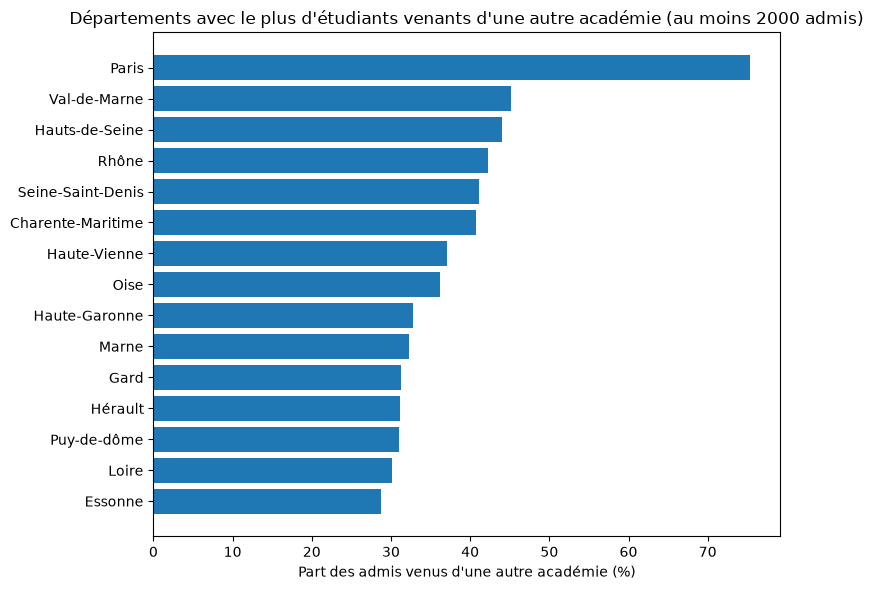

In [13]:
SEUIL = 2000 # donne les mêmes résultats avec 3000, 5000 et plus
fiables = parcoursup_dept_att[parcoursup_dept_att["admis"] >= SEUIL]
fiables = fiables.sort_values("attractivite/mobilité (%)", ascending=False).head(15)

top15_fiables = fiables.sort_values("attractivite/mobilité (%)")

plt.figure(figsize=(8, 6))
plt.barh(top15_fiables["Département de l'établissement"],top15_fiables["attractivite/mobilité (%)"])
plt.xlabel("Part des admis venus d'une autre académie (%)")
plt.title(f"Départements avec le plus d'étudiants venants d'une autre académie (au moins {SEUIL} admis)")
plt.tight_layout()
plt.show()

In [14]:
dept_bac = parcoursup.groupby(["Code départemental de l'établissement", "Département de l'établissement"]).agg(
    admis=("Effectif des admis néo bacheliers", "sum"),
    nb_bac_g=("Effectif des admis néo bacheliers généraux", "sum"),
    nb_bac_t=("Effectif des admis néo bacheliers technologiques", "sum"),
    nb_bac_p=("Effectif des admis néo bacheliers professionnels", "sum"),
).reset_index()

dept_bac["Taux de bacheliers Généraux"] = 100 * dept_bac["nb_bac_g"] / dept_bac["admis"]
dept_bac["Taux de bacheliers Techno"] = 100 * dept_bac["nb_bac_t"] / dept_bac["admis"]
dept_bac["Taux de bacheliers Pro"] = 100 * dept_bac["nb_bac_p"] / dept_bac["admis"]

dept_bac.head()

,Code départemental de l'établissement,Département de l'établissement,admis,nb_bac_g,nb_bac_t,nb_bac_p,Taux de bacheliers Généraux,Taux de bacheliers Techno,Taux de bacheliers Pro
0,01,Ain,1153,560,353,240,48.568951,30.615785,20.815265
1,02,Aisne,1673,661,556,456,39.509863,33.233712,27.256426
2,03,Allier,1328,587,484,257,44.201807,36.445783,19.352410
3,04,Alpes-de-Haute-Provence,201,87,73,41,43.283582,36.318408,20.398010
4,05,Hautes-Alpes,303,164,85,54,54.125413,28.052805,17.821782


Text(0.5, 1.0, 'Taux de bacheliers Pro parmi les admis, par département métropolitain - Parcoursup 2025')

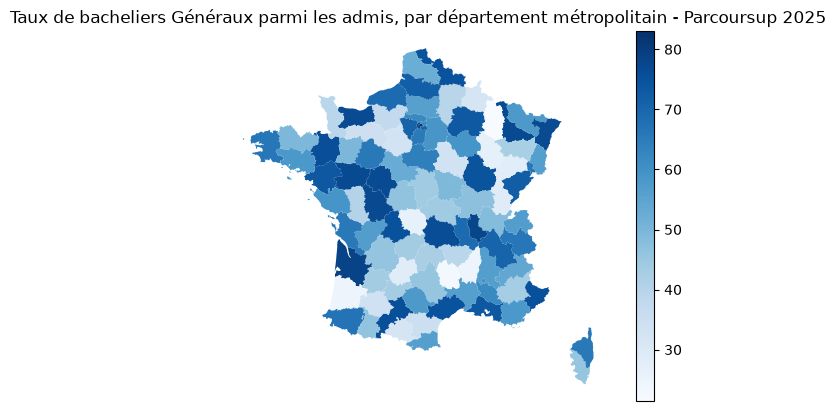

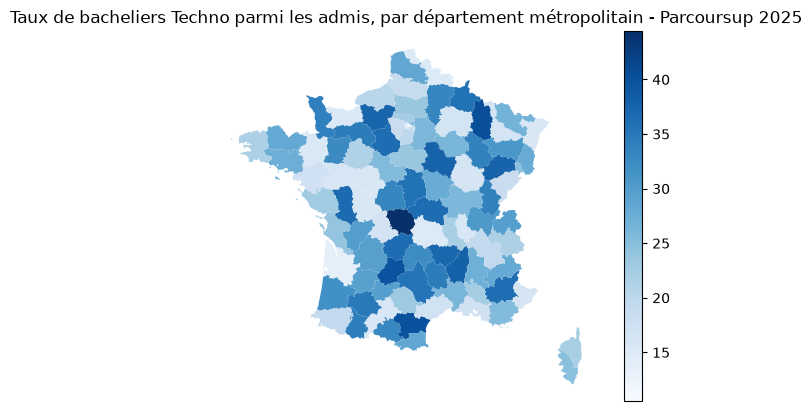

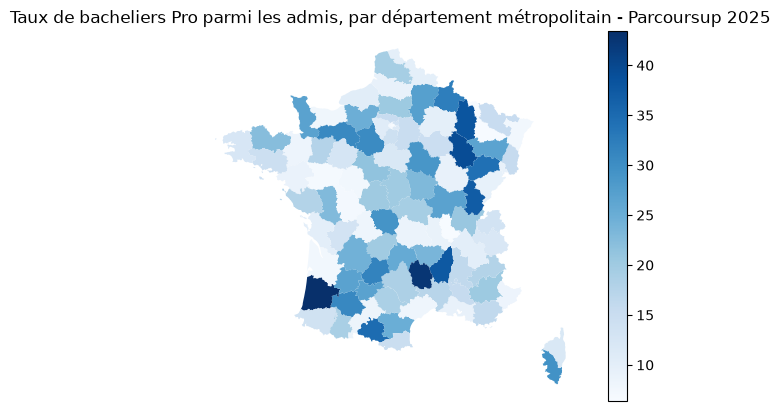

In [15]:
# visualisation avec carte faite à l'aide de l'ia

url = "https://raw.githubusercontent.com/gregoiredavid/france-geojson/master/departements-version-simplifiee.geojson"
france = gpd.read_file(url)

france_metro = france[~france["code"].isin(["971", "972", "973", "974", "976"])].copy()
france_metro = france_metro.rename(columns={"code": "INSEE_DEP"})
france_metro["INSEE_DEP"] = france_metro["INSEE_DEP"].astype(str).str.zfill(2)

dept_bac["Code départemental de l'établissement"] = (
    dept_bac["Code départemental de l'établissement"].astype(str).str.zfill(2)
)

france_metro = france_metro.merge(
    dept_bac,
    left_on="INSEE_DEP",
    right_on="Code départemental de l'établissement",
    how="left",
)

graph_g = france_metro.plot(
    column="Taux de bacheliers Généraux",
    legend=True,
    cmap="Blues",
)
graph_g.set_axis_off()
graph_g.set_title("Taux de bacheliers Généraux parmi les admis, par département métropolitain - Parcoursup 2025")

graph_t = france_metro.plot(
    column="Taux de bacheliers Techno",
    legend=True,
    cmap="Blues",
)
graph_t.set_axis_off()
graph_t.set_title("Taux de bacheliers Techno parmi les admis, par département métropolitain - Parcoursup 2025")

graph_p = france_metro.plot(
    column="Taux de bacheliers Pro",
    legend=True,
    cmap="Blues",
)
graph_p.set_axis_off()
graph_p.set_title("Taux de bacheliers Pro parmi les admis, par département métropolitain - Parcoursup 2025")

Le code suivant a un intérêt si et seulement si les taux de bacs des étudiants 2023 par département reflètent ce deux des actifs sur la même période. C'est une hypothèse qui ne semble pas délirante. C'est le plus suscpetible d'être le cas avec les bacs pro dont la mobilité est sûrement faible. 

edu niveau aca
emploi niveau dep 